# FlipItNews: News Category Classification
Shaikh Mohammed Yaseen | 24CD3036

## 0. Install packages
Run this cell once. When it finishes, **restart the kernel**, then run the rest from the next cell.

In [12]:
%pip install -q --default-timeout=300 tensorflow gensim scikit-learn nltk pandas matplotlib gdown


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Load data and EDA

In [27]:
import os
import re
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix
from gensim.models import Word2Vec
from tensorflow import keras
from tensorflow.keras import layers

nltk.download("stopwords", quiet=True)

True

In [28]:
if not os.path.exists("dataset.csv"):
    import gdown
    gdown.download(id="1POmzYEQZgZVqJO3F_cyNcd4QmoNE_mCv", output="dataset.csv", quiet=False)

df = pd.read_csv("dataset.csv", sep="\t", quoting=3, encoding="utf-8-sig", on_bad_lines="skip")
df = df.rename(columns={"category": "Category", "content": "Article"})[["Category", "Article"]]

TEXT_COL = "Article"
LABEL_COL = "Category"

print(df.shape)
df.head()

Downloading...
From: https://drive.google.com/uc?id=1POmzYEQZgZVqJO3F_cyNcd4QmoNE_mCv
To: d:\5thsem\AIMLDL\lab8\dataset.csv
100%|██████████| 5.08M/5.08M [00:01<00:00, 4.62MB/s]

(2225, 2)


,Category,Article
0,business,Quarterly profits at US media giant TimeWarne...
1,business,The dollar has hit its highest level against ...
2,business,The owners of embattled Russian oil giant Yuk...
3,business,British Airways has blamed high fuel prices f...
4,business,Shares in UK drinks and food firm Allied Dome...


In [29]:
df.info()
print("\nMissing values:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

df = df.dropna().drop_duplicates().reset_index(drop=True)
print("Rows after cleaning:", len(df))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2225 entries, 0 to 2224
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Category  2225 non-null   object
 1   Article   2225 non-null   object
dtypes: object(2)
memory usage: 34.9+ KB

Missing values:
Category    0
Article     0
dtype: int64

Duplicate rows: 133
Rows after cleaning: 2092


Category
business         500
sport            494
politics         395
entertainment    366
tech             337
Name: count, dtype: int64


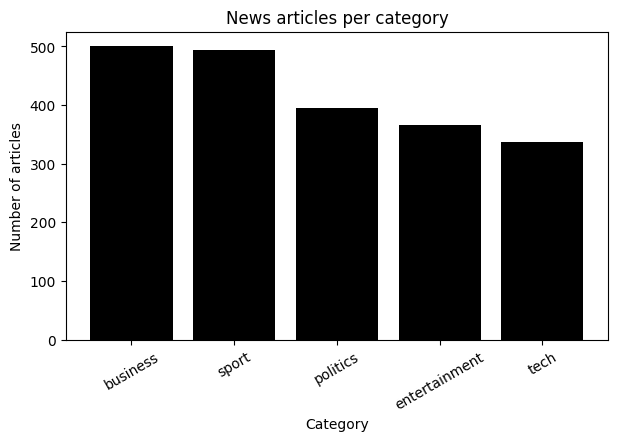

In [30]:
counts = df[LABEL_COL].value_counts()
print(counts)

plt.figure(figsize=(7, 4))
plt.bar(counts.index, counts.values, color="black")
plt.title("News articles per category")
plt.xlabel("Category")
plt.ylabel("Number of articles")
plt.xticks(rotation=30)
plt.show()

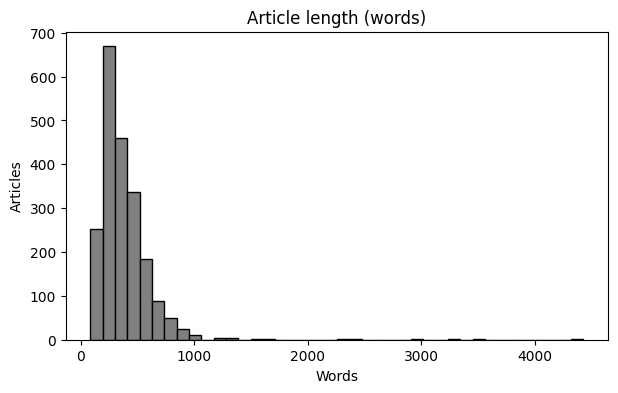

count    2092.000000
mean      378.765774
std       241.941953
min        84.000000
25%       239.000000
50%       324.000000
75%       466.250000
max      4428.000000
Name: word_count, dtype: float64


In [31]:
df["word_count"] = df[TEXT_COL].apply(lambda t: len(t.split()))

plt.figure(figsize=(7, 4))
plt.hist(df["word_count"], bins=40, color="gray", edgecolor="black")
plt.title("Article length (words)")
plt.xlabel("Words")
plt.ylabel("Articles")
plt.show()

print(df["word_count"].describe())

## 2. Preprocessing

In [32]:
stop_words = set(stopwords.words("english"))

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = text.split()
    tokens = [w for w in tokens if w not in stop_words and len(w) > 1]
    return tokens

df["tokens"] = df[TEXT_COL].apply(clean_text)
df["clean"] = df["tokens"].apply(" ".join)

print("Before:", df[TEXT_COL].iloc[0][:200])
print("After :", df["clean"].iloc[0][:200])

Before:  Quarterly profits at US media giant TimeWarner jumped 76% to $1.13bn (£600m) for the three months to December, from $639m year-earlier.  The firm, which is now one of the biggest investors in Google,
After : quarterly profits us media giant timewarner jumped bn three months december year earlier firm one biggest investors google benefited sales high speed internet connections higher advert sales timewarne


In [33]:
le = LabelEncoder()
y = le.fit_transform(df[LABEL_COL])
n_classes = len(le.classes_)
print("Classes:", list(le.classes_))

train_df, test_df, y_train, y_test = train_test_split(
    df, y, test_size=0.2, stratify=y, random_state=42)
print("Train:", len(train_df), " Test:", len(test_df))

Classes: ['business', 'entertainment', 'politics', 'sport', 'tech']
Train: 1673  Test: 419


## Models

In [34]:
bow = CountVectorizer(max_features=5000)
X_train_bow = bow.fit_transform(train_df["clean"]).toarray()
X_test_bow = bow.transform(test_df["clean"]).toarray()

tfidf = TfidfVectorizer(max_features=5000)
X_train_tfidf = tfidf.fit_transform(train_df["clean"]).toarray()
X_test_tfidf = tfidf.transform(test_df["clean"]).toarray()

print("BoW   :", X_train_bow.shape)
print("TF-IDF:", X_train_tfidf.shape)

BoW   : (1673, 5000)
TF-IDF: (1673, 5000)


In [35]:
W2V_SIZE = 100
w2v = Word2Vec(sentences=list(train_df["tokens"]), vector_size=W2V_SIZE,
               window=5, min_count=2, workers=4, seed=42)
print("Word2Vec vocab:", len(w2v.wv))

def doc_vector(tokens):
    vecs = [w2v.wv[w] for w in tokens if w in w2v.wv]
    if len(vecs) == 0:
        return np.zeros(W2V_SIZE)
    return np.mean(vecs, axis=0)

X_train_w2v = np.array([doc_vector(t) for t in train_df["tokens"]])
X_test_w2v = np.array([doc_vector(t) for t in test_df["tokens"]])
print("Word2Vec:", X_train_w2v.shape)

Word2Vec vocab: 15996
Word2Vec: (1673, 100)


## neural network models

In [36]:
EPOCHS = 10
results = []

def evaluate(name, y_true, y_pred):
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_true, y_pred, average="weighted", zero_division=0),
        "F1-score": f1_score(y_true, y_pred, average="weighted", zero_division=0),
    })

def build_nn(input_dim):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(64, activation="relu"),
        layers.Dense(n_classes, activation="softmax"),
    ])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

def train_nn(name, X_train, X_test):
    model = build_nn(X_train.shape[1])
    model.fit(X_train, y_train, epochs=EPOCHS, batch_size=32, validation_split=0.1, verbose=0)
    y_pred = model.predict(X_test, verbose=0).argmax(axis=1)
    evaluate(name, y_test, y_pred)
    print(name, "done, accuracy =", round(results[-1]["Accuracy"], 4))

train_nn("NN + BoW", X_train_bow, X_test_bow)
train_nn("NN + TF-IDF", X_train_tfidf, X_test_tfidf)
train_nn("NN + Word2Vec", X_train_w2v, X_test_w2v)

NN + BoW done, accuracy = 0.9737
NN + TF-IDF done, accuracy = 0.9737
NN + Word2Vec done, accuracy = 0.8138


## 5. RNN model

In [37]:
MAX_LEN = 200

word_index = {}
for tokens in train_df["tokens"]:
    for w in tokens:
        if w not in word_index:
            word_index[w] = len(word_index) + 2

def to_sequences(token_lists):
    seqs = [[word_index.get(w, 1) for w in tokens] for tokens in token_lists]
    return keras.utils.pad_sequences(seqs, maxlen=MAX_LEN, padding="pre", truncating="post")

X_train_seq = to_sequences(train_df["tokens"])
X_test_seq = to_sequences(test_df["tokens"])

vocab_size = len(word_index) + 2
embedding_matrix = np.zeros((vocab_size, W2V_SIZE))
for w, i in word_index.items():
    if w in w2v.wv:
        embedding_matrix[i] = w2v.wv[w]

print("Sequences:", X_train_seq.shape, " Vocab size:", vocab_size)

Sequences: (1673, 200)  Vocab size: 25201


In [38]:
rnn = keras.Sequential([
    layers.Input(shape=(MAX_LEN,)),
    layers.Embedding(vocab_size, W2V_SIZE,
                     embeddings_initializer=keras.initializers.Constant(embedding_matrix)),
    layers.LSTM(64),
    layers.Dropout(0.3),
    layers.Dense(n_classes, activation="softmax"),
])
rnn.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
rnn.summary()

rnn.fit(X_train_seq, y_train, epochs=EPOCHS, batch_size=32, validation_split=0.1, verbose=2)

y_pred_rnn = rnn.predict(X_test_seq, verbose=0).argmax(axis=1)
evaluate("RNN (LSTM) + Word2Vec", y_test, y_pred_rnn)

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 100)       │     2,520,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        42,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,562,665 (9.78 MB)

 Trainable params: 2,562,665 (9.78 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
48/48 - 11s - 221ms/step - accuracy: 0.4804 - loss: 1.2659 - val_accuracy: 0.5714 - val_loss: 1.0233
Epoch 2/10
48/48 - 11s - 223ms/step - accuracy: 0.6930 - loss: 0.8199 - val_accuracy: 0.7440 - val_loss: 0.8985
Epoch 3/10
48/48 - 15s - 321ms/step - accuracy: 0.6837 - loss: 0.7951 - val_accuracy: 0.7202 - val_loss: 0.6657
Epoch 4/10
48/48 - 17s - 349ms/step - accuracy: 0.8047 - loss: 0.5465 - val_accuracy: 0.8155 - val_loss: 0.5888
Epoch 5/10
48/48 - 9s - 197ms/step - accuracy: 0.8571 - loss: 0.5035 - val_accuracy: 0.8512 - val_loss: 0.5567
Epoch 6/10
48/48 - 9s - 195ms/step - accuracy: 0.8611 - loss: 0.4388 - val_accuracy: 0.5714 - val_loss: 1.2059
Epoch 7/10
48/48 - 10s - 217ms/step - accuracy: 0.6997 - loss: 1.0326 - val_accuracy: 0.5952 - val_loss: 1.2483
Epoch 8/10
48/48 - 7s - 142ms/step - accuracy: 0.6831 - loss: 0.7936 - val_accuracy: 0.7738 - val_loss: 0.8089
Epoch 9/10
48/48 - 11s - 232ms/step - accuracy: 0.8711 - loss: 0.4517 - val_accuracy: 0.8571 - val_loss: 0.

## 6. Compare models

                   Model  Accuracy  Precision  Recall  F1-score
0               NN + BoW    0.9737     0.9745  0.9737    0.9739
1            NN + TF-IDF    0.9737     0.9744  0.9737    0.9739
2          NN + Word2Vec    0.8138     0.8295  0.8138    0.8015
3  RNN (LSTM) + Word2Vec    0.9117     0.9142  0.9117    0.9124


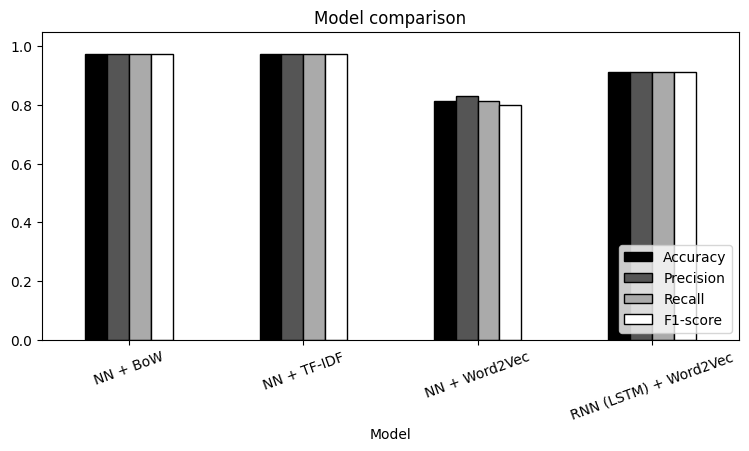

Best model: NN + BoW | F1 = 0.9739


In [39]:
results_df = pd.DataFrame(results).round(4)
print(results_df)

results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1-score"]].plot(
    kind="bar", figsize=(9, 4), colormap="gray", edgecolor="black")
plt.title("Model comparison")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.show()

best = results_df.sort_values("F1-score", ascending=False).iloc[0]
print("Best model:", best["Model"], "| F1 =", best["F1-score"])

               precision    recall  f1-score   support

     business       0.98      0.96      0.97       100
entertainment       0.82      0.88      0.85        73
     politics       0.96      0.90      0.93        79
        sport       0.92      0.90      0.91        99
         tech       0.86      0.91      0.89        68

     accuracy                           0.91       419
    macro avg       0.91      0.91      0.91       419
 weighted avg       0.91      0.91      0.91       419



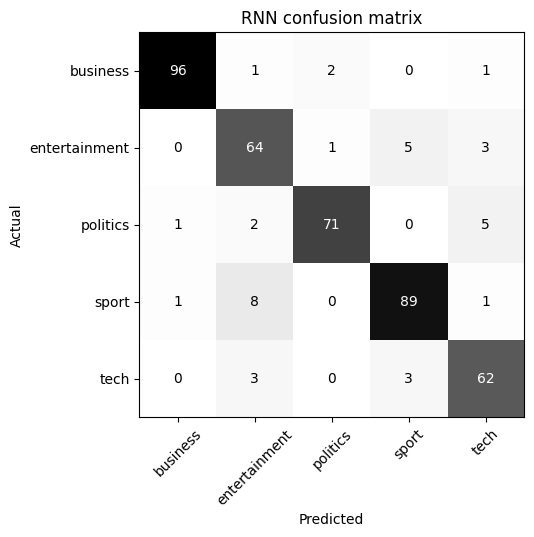

In [40]:
print(classification_report(y_test, y_pred_rnn, target_names=le.classes_))

cm = confusion_matrix(y_test, y_pred_rnn)
plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="gray_r")
plt.xticks(range(n_classes), le.classes_, rotation=45)
plt.yticks(range(n_classes), le.classes_)
for i in range(n_classes):
    for j in range(n_classes):
        plt.text(j, i, cm[i, j], ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("RNN confusion matrix")
plt.show()

## Saving

In [41]:
rnn.save("rnn_model.keras")
with open("rnn_assets.pkl", "wb") as f:
    pickle.dump({"word_index": word_index, "classes": list(le.classes_), "max_len": MAX_LEN}, f)

def predict_category(text):
    tokens = clean_text(text)
    seq = to_sequences([tokens])
    probs = rnn.predict(seq, verbose=0)[0]
    return le.classes_[probs.argmax()], float(probs.max())

print(predict_category("The team won the final match with a late goal"))
print(predict_category("The government announced a new budget for the coming year"))

('sport', 0.6760405898094177)
('business', 0.8727292418479919)


In [ ]:
import sys
print(sys.executable)

c:\Users\OMEN\miniconda3\envs\ml_env\python.exe
